# Web search engines, one at a time (23 Nov 2026)

Which search engines answer this machine, how much of what they return is on the subject, and whether they
find the pages a fact-checker cited. **Retrieval only**: no model and no verdict, so no figure of the thesis moves.

- **Queries**: the `proposition` query the pipeline itself sent for each claim of two recorded **train** runs:
  18 AVeriTeC train claims in English (dev is never tuned on) and 8 claims of the custom set's train half in
  Spanish, one per article. 26 queries, each sent to every engine on its own (`engines=`), one at a time per
  engine with a 2-3 s pause.
- **Instances**: SearXNG **2026.11.2**, the version `docker/docker-compose.yml` pins. `allowlist` is this repo's
  own `docker/searxng/settings.yml`, exactly what the app gets once the stack runs from this folder.
  `candidates` is a throwaway instance with every default engine (`searxng-probe.yml`). A first pass ran on
  **2026.9.8**, the image the stack running today was started with (from the deleted `../inspiring-news-map`).
- **Collected by** `scripts/probe_search_engines.py`. This notebook only reads its files.

What "on the subject" means is the app's own rule (`backend/src/services/search.py`, `MIN_QUERY_COVERAGE`): a
result's title and summary hold at least 35% of the query's words.

In [1]:
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("data")

# The editable choices.
ON_TOPIC = 0.35   # search.MIN_QUERY_COVERAGE: the share of the query's words a result must hold
FILES = {
    "2026.11.2": ["probe-2026-11-23-allowlist.jsonl", "probe-2026-11-23-candidates.jsonl"],
    "2026.9.8": ["probe-2026-11-23-searxng-2026.9.8.jsonl"],
}
ALLOWLIST = ["duckduckgo", "startpage", "mojeek", "yahoo", "google", "brave", "yep", "bing news", "wikipedia"]

rows = []
for image, names in FILES.items():
    for name in names:
        for line in (DATA / name).read_text().splitlines():
            row = json.loads(line)
            row["image"] = image
            rows.append(row)

df = pd.DataFrame(rows)
df["answered"] = df["bestCoverage"].fillna(0) >= ON_TOPIC
df["english"] = df["set"] == "averitec-train"
print(len(df), "requests;", df.groupby("image")["engine"].nunique().to_dict(), "engines;",
      df["id"].nunique(), "queries")

1690 requests; {'2026.11.2': 33, '2026.9.8': 32} engines; 26 queries


## Every engine on the pinned image (2026.11.2)

In [2]:
def reasons(group):
    failed = group[group["status"] != "ok"]
    text = failed["reason"].where(failed["reason"] != "", failed["status"])
    return "; ".join(f"{k} ×{v}" for k, v in text.str.replace(r"^[^:]+: ", "", regex=True).str.replace("Suspended: ", "").value_counts().head(2).items())

def table(frame):
    out = frame.groupby("engine").apply(lambda g: pd.Series({
        "allowlist": "yes" if g.name in ALLOWLIST else "",
        "answered": f"{g['answered'].sum()}/{len(g)}",
        "on-topic of top 10": round(g["onTopic"].mean(), 1),
        "results": int(g["count"].median()),
        "seconds": round(g["seconds"].median(), 2),
        "cited site in top 10 (en)": f"{g.loc[g['english'], 'goldSite'].sum()}/{g['english'].sum()}",
        "source article found (es)": f"{g.loc[~g['english'], 'goldPage'].sum()}/{(~g['english']).sum()}",
        "fact-checks in top 10": round(g["factChecks"].mean(), 1),
        "why it failed": reasons(g),
    }), include_groups=False)
    return out.sort_values(["on-topic of top 10"], ascending=False)

pinned = table(df[df["image"] == "2026.11.2"])
pinned

,allowlist,answered,on-topic of top 10,results,seconds,cited site in top 10 (en),source article found (es),fact-checks in top 10,why it failed
engine,,,,,,,,,
privacywall,,26/26,7.4,10,0.51,6/18,2/8,0.9,
(all together),,26/26,6.5,40,3.02,7/18,2/8,0.8,
duckduckgo web,,23/26,6.2,10,0.75,7/18,1/8,0.5,timeout ×3
yandex,,25/26,5.9,15,0.59,4/18,1/8,0.4,
duckduckgo,yes,20/26,5.5,10,0.66,7/18,1/8,0.6,CAPTCHA ×6
yahoo,yes,26/26,4.9,7,0.72,8/18,2/8,0.7,
bing,,8/26,1.8,10,0.22,2/18,2/8,0.0,
duckduckgo news,,11/26,1.5,0,0.33,0/18,1/8,0.2,empty ×14
bing news,yes,12/26,1.4,0,0.23,0/18,0/8,0.1,parsing error ×14


Read the columns as:
- **answered**: the queries whose best result held 35% of the query's words. This is the app's own test of
  whether a search answered at all.
- **on-topic of top 10**: how many of the first ten results passed that test, averaged over all 26 queries
  (failures count as 0).
- **cited site in top 10 (en)**: for AVeriTeC, whether a page from a site its annotators cited is among the first
  ten. The exact cited page was almost never found by any engine (0-1 of 18).
- **source article found (es)**: for the custom set, whether the article the claim was taken from came back.

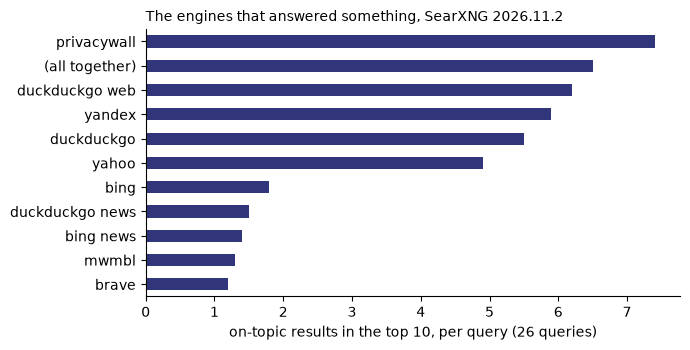

In [3]:
working = pinned[pinned["on-topic of top 10"] >= 1]
ax = working["on-topic of top 10"].sort_values().plot.barh(figsize=(7, 3.6), color="#31357A")
ax.set_xlabel("on-topic results in the top 10, per query (26 queries)")
ax.set_ylabel("")
ax.set_title("The engines that answered something, SearXNG 2026.11.2", loc="left", fontsize=10)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()

## What the app's search gets: every allowlisted engine together

In [4]:
mix = df[(df["image"] == "2026.11.2") & (df["engine"] == "(all together)")]
filled = pd.Series([e for results in mix["results"] for r in results for e in (r["engines"] or [])]).value_counts()
failing = pd.Series([part.split(":")[0].strip() for text in mix["reason"] for part in text.split(";") if part]).value_counts()
print("Who filled the top 10s:", filled.to_dict())
print("Who failed, in how many of the 26 searches:", failing.to_dict())
print("Seconds per search:", mix["seconds"].describe()[["50%", "max"]].round(2).to_dict(),
      "-", (mix["seconds"] >= 2.9).sum(), "of 26 waited the full 3 s timeout")

Who filled the top 10s: {'duckduckgo': 200, 'yahoo': 151, 'crossref': 18, 'arxiv': 7, 'brave': 2, 'semantic scholar': 1}
Who failed, in how many of the 26 searches: {'google': 26, 'pubmed': 26, 'yep': 26, 'brave': 25, 'semantic scholar': 21, 'crossref': 4, 'yahoo': 3, 'arxiv': 2}


Seconds per search: {'50%': 3.02, 'max': 3.02} - 15 of 26 waited the full 3 s timeout


## Are they different indexes? Overlap of their top 10s

In [5]:
from urllib.parse import urlsplit

def page(url):
    parts = urlsplit(url or "")
    return parts.netloc.lower().removeprefix("www.") + parts.path.rstrip("/")

ENGINES = ["duckduckgo", "duckduckgo web", "yahoo", "privacywall", "yandex", "bing"]
pin = df[df["image"] == "2026.11.2"]
pages = {(r.engine, r.id): {page(x["url"]) for x in r.results} for r in pin.itertuples()}

def overlap(a, b):
    shares = [len(pages[a, q] & pages[b, q]) / len(pages[a, q]) for q in pin["id"].unique()
              if pages.get((a, q)) and pages.get((b, q))]
    return round(sum(shares) / len(shares), 2) if shares else None

pd.DataFrame({b: {a: overlap(a, b) for a in ENGINES} for b in ENGINES}).rename_axis("share of this engine's pages…")

,duckduckgo,duckduckgo web,yahoo,privacywall,yandex,bing
share of this engine's pages…,,,,,,
duckduckgo,1.00,0.74,0.50,0.47,0.07,0.25
duckduckgo web,0.74,1.00,0.52,0.44,0.06,0.23
yahoo,0.71,0.75,1.00,0.54,0.07,0.19
privacywall,0.47,0.44,0.38,1.00,0.06,0.12
yandex,0.07,0.06,0.05,0.06,1.00,0.02
bing,0.25,0.23,0.13,0.12,0.02,1.00


Each cell is the share of the row engine's top-10 pages that the column engine also returned, on the queries both answered.

## The stack running today: the same engines on SearXNG 2026.9.8

In [6]:
old = table(df[df["image"] == "2026.9.8"])
compare = pd.DataFrame({
    "2026.9.8 answered": old["answered"],
    "2026.9.8 on-topic": old["on-topic of top 10"],
    "2026.11.2 answered": pinned["answered"],
    "2026.11.2 on-topic": pinned["on-topic of top 10"],
}).loc[[e for e in ALLOWLIST + ["bing", "yandex", "privacywall", "duckduckgo web"] if e in old.index]]
compare

,2026.9.8 answered,2026.9.8 on-topic,2026.11.2 answered,2026.11.2 on-topic
engine,,,,
duckduckgo,22/26,5.6,20/26,5.5
startpage,0/26,0.0,0/26,0.0
mojeek,0/26,0.0,4/26,0.8
yahoo,0/26,0.0,26/26,4.9
google,0/26,0.0,0/26,0.0
brave,0/26,0.0,5/26,1.2
yep,0/26,0.0,0/26,0.0
bing news,11/26,1.3,12/26,1.4
wikipedia,0/26,0.0,0/26,0.0


## What it says

1. **Two engines carry the allowlist.** On the pinned image, every web result in the app's top 10s came from
   DuckDuckGo (200) or Yahoo (151); the rest were papers. Google ("access denied") and Yep (HTTP error) refused
   all 26 queries. Brave answered 5 and Mojeek 4 before SearXNG suspended them for "too many requests" and
   "access denied". Startpage hit a CAPTCHA on every query, and Bing News failed to parse 14 of 26.
2. **Startpage and Mojeek are switched off upstream since SearXNG 2026.11** (`inactive: true`, "uses a Proof Of
   Work captcha"). The allowlist names them, but on the image compose pins they never load: they were measured
   here only by switching them back on. Mojeek's own page answers this machine with a CAPTCHA.
3. **The best single engine is one the allowlist leaves out**: PrivacyWall answered 26 of 26, with 7.4
   on-topic results per query. About half its pages are also DuckDuckGo's or Yahoo's, and on 2026.9.8 it
   refused this machine.
4. **The working engines are not independent.** 71-75% of Yahoo's top 10 is in DuckDuckGo's, and
   `duckduckgo web` is DuckDuckGo again (74%). The September comment's "four independent indexes" is now in
   practice one family. **Yandex** is the exception: 25 of 26 answered, 5.9 on-topic results per query, and
   2-7% overlap with any other engine.
5. **Bing still reads only the first word**: it returns results for every query, but only 8 of 26 are on the subject.
6. **Every search waits on a timeout**: PubMed timed out in all 26 searches, so 15 of 26 took the full 3 s.
7. **Wikipedia answers exact titles only.** It returned nothing for a claim-length query, but it may still serve
   the short anchor queries, which this test did not send.
8. **The running stack is worse**: on 2026.9.8 Yahoo fails to parse, so the stack running today gets only
   DuckDuckGo, plus Bing's first-word answers.

**Not shown**: whether any of this changes a verdict. That needs a searched run on train with the new
allowlist, against one with the old, compared as `/fact-check-change` says. This was one machine on one day, with
26 queries: engines block by address, and the 3 Nov measurement came out differently.